## Figure 3, environment field

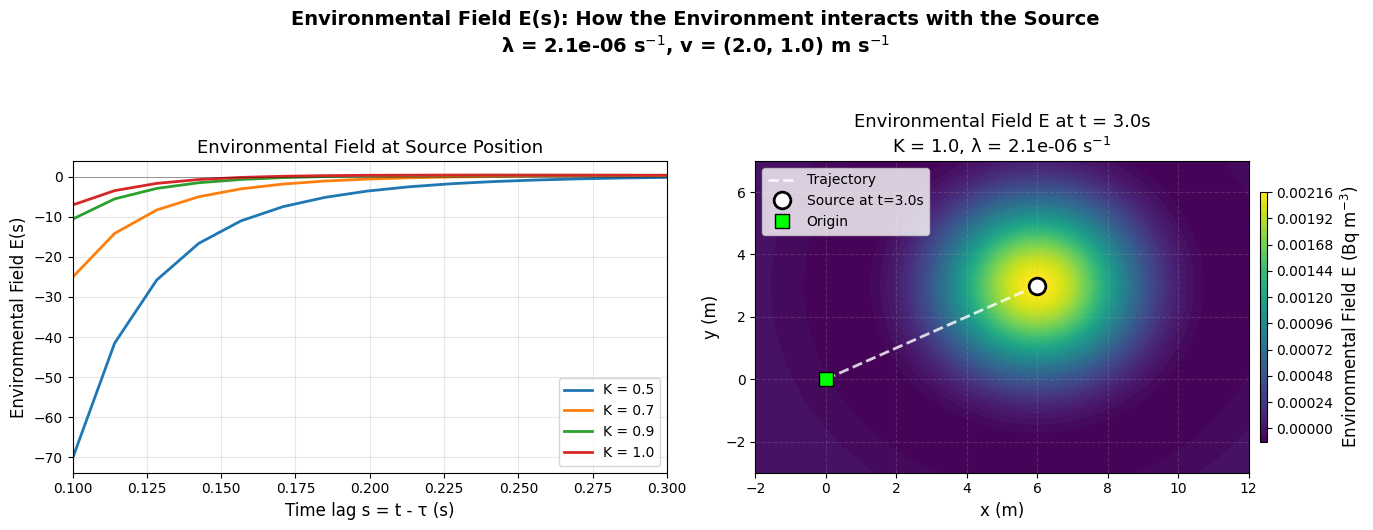

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
F0 = 1.0
lambd = 2.1e-6  # Radon-222 decay constant (s^-1)
vx, vy = 2.0, 1.0
x0, y0 = 0.0, 0.0

# Time lags - start from larger value to avoid singularities
s = np.linspace(0.1, 10, 700)

# Diffusion coefficients to vary
K_values = [0.5, 0.7, 0.9, 1.0]

# Detector position
x_det, y_det = 5.0, 3.0

# Figure: 1 row, 2 columns
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ============================================
# Left Plot: Environmental Field E(s) at Different K
# ============================================
ax = axes[0]

# At the source position (x = x0, y = y0)
for K in K_values:
    # E accumulates the dissipative term L_d S acting on the source
    # L_d S = -K ∇²S + λS. For a Gaussian source, this gives the bracket term
    bracket = -1 / (4 * K * s**2) + 3 / (2 * s) + lambd
    E = 1 / (4 * np.pi * K * s)**(3/2) * np.exp(-lambd * s) * bracket
    ax.plot(s, E, label=f'K = {K}', linewidth=2)

ax.set_xlabel('Time lag s = t - τ (s)', fontsize=12)
ax.set_ylabel('Environmental Field E(s)', fontsize=12)
ax.set_title('Environmental Field at Source Position', fontsize=13)
ax.grid(True, alpha=0.3)
ax.legend(fontsize=10)
ax.set_xlim(0.1, 0.3)
ax.axhline(y=0, color='black', linestyle='-', linewidth=0.5, alpha=0.5)

# ============================================
# Right Plot: 2D Environmental Field with Trajectory
# ============================================
ax = axes[1]

# Create grid
x = np.linspace(-2, 12, 200)
y = np.linspace(-3, 7, 200)
X, Y = np.meshgrid(x, y)

# Fixed time
t_fixed = 3.0
K_fixed = 1.0

# Source position at time t
xs = x0 + vx * t_fixed
ys = y0 + vy * t_fixed

# Calculate E at fixed time (integrated over all past emissions)
# For visualization, we compute E as the accumulated dissipative effect
r2 = (X - xs)**2 + (Y - ys)**2
bracket = -r2 / (4 * K_fixed * t_fixed**2) + 3 / (2 * t_fixed) + lambd
E_field = F0 / (4 * np.pi * K_fixed * t_fixed)**(3/2) * np.exp(-r2 / (4 * K_fixed * t_fixed)) * np.exp(-lambd * t_fixed) * bracket

# Plot E with contour
im = ax.contourf(X, Y, E_field, levels=60, cmap='viridis')

# Add trajectory
traj_x = np.linspace(x0, xs, 50)
traj_y = np.linspace(y0, ys, 50)
ax.plot(traj_x, traj_y, '--', color='white', linewidth=2, alpha=0.8, label='Trajectory')

# Source position
ax.plot(xs, ys, 'o', color='white', markersize=12, markeredgewidth=2, markeredgecolor='black', label='Source at t=3.0s')
ax.plot(x0, y0, 's', color='lime', markersize=10, markeredgecolor='black', label='Origin')

# Add colorbar
cbar = fig.colorbar(im, ax=ax, orientation='vertical', pad=0.02, aspect=40, shrink=0.8)
cbar.set_label('Environmental Field E (Bq m$^{-3}$)', fontsize=12)

ax.set_xlabel('x (m)', fontsize=12)
ax.set_ylabel('y (m)', fontsize=12)
ax.set_title(f'Environmental Field E at t = {t_fixed:.1f}s\nK = {K_fixed}, λ = {lambd:.1e} s$^{{-1}}$', fontsize=13)
ax.set_xlim(-2, 12)
ax.set_ylim(-3, 7)
ax.grid(True, linestyle='--', alpha=0.2)
ax.legend(loc='upper left', fontsize=10)

plt.suptitle('Environmental Field E(s): How the Environment interacts with the Source\n'
             f'λ = {lambd:.1e} s$^{{-1}}$, v = ({vx:.1f}, {vy:.1f}) m s$^{{-1}}$', 
             fontsize=14, fontweight='bold', y=1.05)
plt.tight_layout()



## Figure 2, memory field

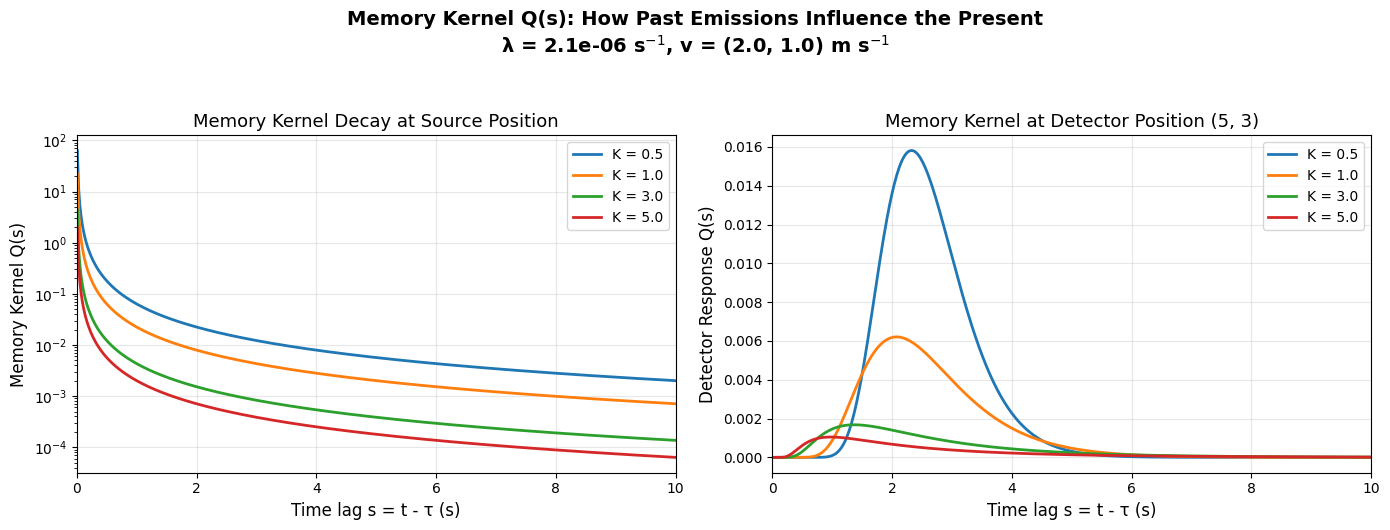

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
F0 = 1.0
lambd = 2.1e-6  # Radon-222 decay constant (s^-1)
vx, vy = 2.0, 1.0
x0, y0 = 0.0, 0.0

# Time lags
s = np.linspace(0.01, 10, 500)

# Diffusion coefficients to vary
K_values = [0.5, 1.0, 3.0, 5.0]

# Detector position
x_det, y_det = 5.0, 3.0

# Figure: 1 row, 2 columns
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ============================================
# Left Plot: Memory Kernel Q(s) at Different K
# ============================================
ax = axes[0]

# At the source position (x = x0, y = y0)
for K in K_values:
    Q = 1 / (4 * np.pi * K * s)**(3/2) * np.exp(-lambd * s)
    ax.plot(s, Q, label=f'K = {K}', linewidth=2)

ax.set_xlabel('Time lag s = t - τ (s)', fontsize=12)
ax.set_ylabel('Memory Kernel Q(s)', fontsize=12)
ax.set_title('Memory Kernel Decay at Source Position', fontsize=13)
ax.set_yscale('log')
ax.grid(True, alpha=0.3)
ax.legend(fontsize=10)
ax.set_xlim(0, 10)

# ============================================
# Right Plot: Detector Response at Different K
# ============================================
ax = axes[1]

for K in K_values:
    xs = x0 + vx * s
    ys = y0 + vy * s
    r2 = (x_det - xs)**2 + (y_det - ys)**2
    Q_det = 1 / (4 * np.pi * K * s)**(3/2) * np.exp(-r2 / (4 * K * s)) * np.exp(-lambd * s)
    ax.plot(s, Q_det, label=f'K = {K}', linewidth=2)

ax.set_xlabel('Time lag s = t - τ (s)', fontsize=12)
ax.set_ylabel('Detector Response Q(s)', fontsize=12)
ax.set_title(f'Memory Kernel at Detector Position ({x_det:.0f}, {y_det:.0f})', fontsize=13)
ax.grid(True, alpha=0.3)
ax.legend(fontsize=10)
ax.set_xlim(0, 10)

plt.suptitle('Memory Kernel Q(s): How Past Emissions Influence the Present\n'
             f'λ = {lambd:.1e} s$^{{-1}}$, v = ({vx:.1f}, {vy:.1f}) m s$^{{-1}}$', 
             fontsize=14, fontweight='bold', y=1.05)
plt.tight_layout()



### Figure 1 source field

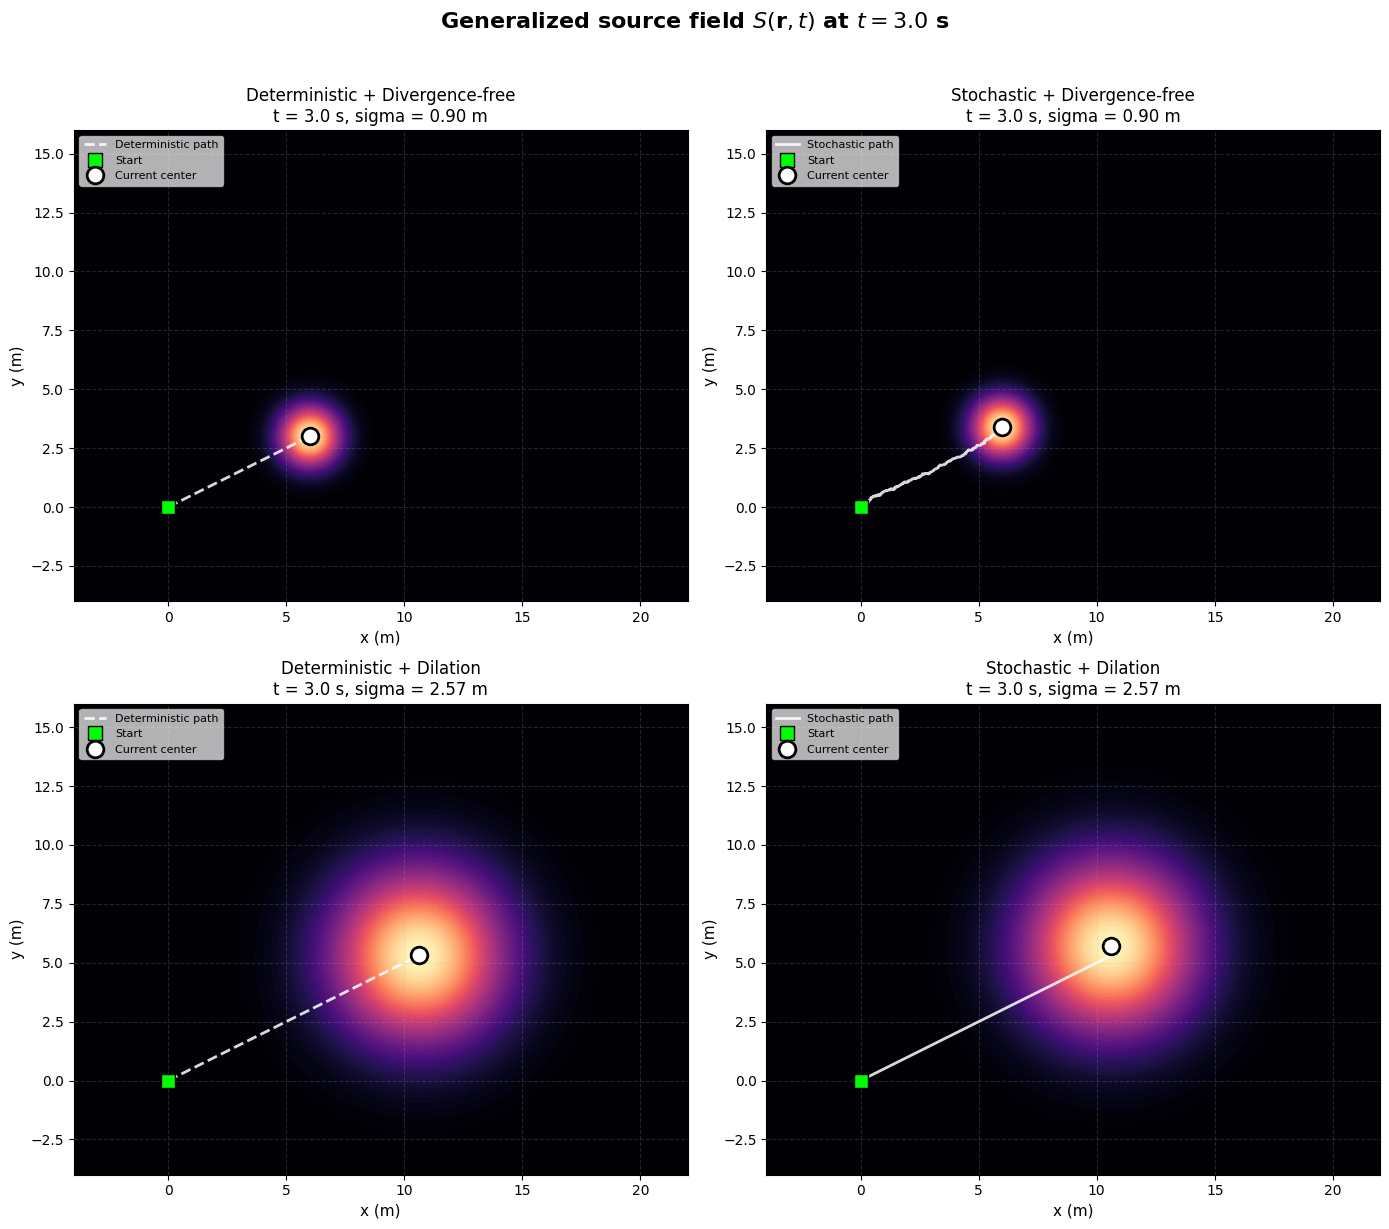


Numerical verification:
------------------------
t = 3.00 s
sigma0              = 0.9000 m
sigma (div-free)    = 0.9000 m
sigma (dilation)    = 2.5719 m
sigma0*exp(alpha*t) = 2.5719 m

Case 1 (det, div-free)     M_S = 19.0000  (target 19.0000)   center = (  6.00,   3.00) m   sigma = 0.900 m
Case 2 (sto, div-free)     M_S = 19.0000  (target 19.0000)   center = (  5.98,   3.39) m   sigma = 0.900 m
Case 3 (det, dilation)     M_S = 18.9969  (target 19.0000)   center = ( 10.62,   5.31) m   sigma = 2.572 m
Case 4 (sto, dilation)     M_S = 18.9978  (target 19.0000)   center = ( 10.60,   5.69) m   sigma = 2.572 m


In [3]:
"""
Generalized source field S(r,t) for QSER, under conservative form.

Governing equation for the source field:
    dS/dt + div(v S) = F
with F = F0 * delta(r - r0) * delta(t).

Four cases are shown:
  (1) Deterministic, divergence-free   --> rigid translation, constant width
  (2) Stochastic,    divergence-free   --> wobbly translation, constant width
  (3) Deterministic, dilation + flow   --> translation + exponential expansion
  (4) Stochastic,    dilation + flow   --> wobbling + exponential expansion

In all cases, total mass M_S(t) = F0 * H(t) is conserved. This is
verified numerically and printed at the end.

The shape function is NOT prescribed. In cases (1)-(2) it is frozen in
the lab frame because div(v) = 0. In cases (3)-(4) it expands as
sigma(t) = sigma0 * exp(alpha * t), which is the exact solution of the
continuity equation for the dilation flow v = alpha * r + u.

Reference for the center trajectory in the dilation + translation flow:
    d(xi)/dt = alpha * xi + u
    xi(t) = xi(0) * exp(alpha*t) + (u/alpha) * (exp(alpha*t) - 1)
"""

import numpy as np
import matplotlib.pyplot as plt

# ----------------------------------------------------------------------
# Parameters
# ----------------------------------------------------------------------
F0      = 19.0          # total activity (Bq)
x0, y0  = 0.0, 0.0      # initial source position (m)
sigma0  = 0.9           # initial width of the Gaussian (m)

# Divergence-free velocity (cases 1-2)
vx_mean = 2.0
vy_mean = 1.0

# Dilation rate and uniform translation (cases 3-4).
#   v = alpha * r + u    -->    div(v) = 2*alpha
alpha   = 0.35          # 1/s
u_x     = 2.0           # uniform translation added to the dilation
u_y     = 1.0

# Stochastic noise strength for velocity (cases 2 and 4)
sigma_v = 1.5

# Grid for plotting.  Expanded so the dilated blob is fully contained.
x = np.linspace(-4, 22, 700)
y = np.linspace(-4, 16, 700)
X, Y = np.meshgrid(x, y)

# Time of the snapshot
t = 3.0

# ----------------------------------------------------------------------
# Trajectories
# ----------------------------------------------------------------------
# Deterministic trajectory for divergence-free case
xi_df_det_x = x0 + vx_mean * t
xi_df_det_y = y0 + vy_mean * t

# Stochastic trajectory for divergence-free case
np.random.seed(42)
n_steps  = 600
dt       = 0.01
t_grid   = np.arange(n_steps) * dt

# Random velocity increments (constant in space, so div(v) = 0)
vx_noise = np.random.randn(n_steps) * sigma_v
vy_noise = np.random.randn(n_steps) * sigma_v
vx_t = vx_mean + vx_noise
vy_t = vy_mean + vy_noise

# Integrate velocity to get position along the trajectory
x_traj = x0 + np.cumsum(vx_t) * dt
y_traj = y0 + np.cumsum(vy_t) * dt

# Index corresponding to time t
idx = int(t / dt)

# Stochastic trajectory position at time t
xi_df_sto_x = x_traj[idx]
xi_df_sto_y = y_traj[idx]

# ----------------------------------------------------------------------
# Dilation + translation trajectories
# ----------------------------------------------------------------------
# Center trajectory: xi(t) = xi(0)*exp(alpha*t) + (u/alpha)*(exp(alpha*t)-1)
exp_at = np.exp(alpha * t)
xi_dil_det_x = x0 * exp_at + (u_x / alpha) * (exp_at - 1.0)
xi_dil_det_y = y0 * exp_at + (u_y / alpha) * (exp_at - 1.0)

# For the stochastic dilation case, use the same deterministic center
# trajectory but superimpose the stochastic wander from the divergence-free
# case.  This is a simplified illustration; a fully consistent stochastic
# dilation field would require a stochastic flow map, which is left for
# future work.
xi_dil_sto_x = xi_dil_det_x + (xi_df_sto_x - (x0 + vx_mean * t))
xi_dil_sto_y = xi_dil_det_y + (xi_df_sto_y - (y0 + vy_mean * t))

# ----------------------------------------------------------------------
# Shape functions
# ----------------------------------------------------------------------
sigma_df  = sigma0                          # divergence-free: constant
sigma_dil = sigma0 * np.exp(alpha * t)      # dilation: exponential growth

def gaussian_2d(X, Y, xc, yc, sigma, F0):
    r2 = (X - xc) ** 2 + (Y - yc) ** 2
    return F0 / (2 * np.pi * sigma ** 2) * np.exp(-r2 / (2 * sigma ** 2))

# ----------------------------------------------------------------------
# Four cases
# ----------------------------------------------------------------------
S1 = gaussian_2d(X, Y, xi_df_det_x,  xi_df_det_y,  sigma_df,  F0)
S2 = gaussian_2d(X, Y, xi_df_sto_x,  xi_df_sto_y,  sigma_df,  F0)
S3 = gaussian_2d(X, Y, xi_dil_det_x, xi_dil_det_y, sigma_dil, F0)
S4 = gaussian_2d(X, Y, xi_dil_sto_x, xi_dil_sto_y, sigma_dil, F0)

# ----------------------------------------------------------------------
# Plot
# ----------------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

# Build smooth trajectories for the dilation cases
tt = np.linspace(0, t, 200)
exp_tt = np.exp(alpha * tt)
xi_dil_path_x = x0 * exp_tt + (u_x / alpha) * (exp_tt - 1.0)
xi_dil_path_y = y0 * exp_tt + (u_y / alpha) * (exp_tt - 1.0)

panels = [
    (S1, xi_df_det_x,  xi_df_det_y,  sigma_df,
     'Deterministic + Divergence-free',
     np.array([x0, xi_df_det_x]), np.array([y0, xi_df_det_y]),
     'dashed'),
    (S2, xi_df_sto_x,  xi_df_sto_y,  sigma_df,
     'Stochastic + Divergence-free',
     x_traj[:idx+1], y_traj[:idx+1],
     'solid'),
    (S3, xi_dil_det_x, xi_dil_det_y, sigma_dil,
     'Deterministic + Dilation',
     xi_dil_path_x, xi_dil_path_y,
     'dashed'),
    (S4, xi_dil_sto_x, xi_dil_sto_y, sigma_dil,
     'Stochastic + Dilation',
     xi_dil_path_x, xi_dil_path_y,
     'solid'),
]

for ax, (S, xs, ys, sig, title, traj_x, traj_y, style) in zip(axes.flat, panels):
    ax.contourf(X, Y, S, levels=80, cmap='magma')

    # Trajectory
    if style == 'dashed':
        ax.plot(traj_x, traj_y, '--', color='white', linewidth=2.0,
                alpha=0.85, label='Deterministic path')
    else:
        ax.plot(traj_x, traj_y, '-', color='white', linewidth=2.0,
                alpha=0.85, label='Stochastic path')

    # Start and current center
    ax.plot(traj_x[0], traj_y[0], 's', color='lime', markersize=10,
            markeredgecolor='black', label='Start')
    ax.plot(xs, ys, 'o', color='white', markersize=12,
            markeredgewidth=2, markeredgecolor='black', label='Current center')

    ax.set_xlabel('x (m)', fontsize=11)
    ax.set_ylabel('y (m)', fontsize=11)
    ax.set_title(f'{title}\nt = {t:.1f} s, sigma = {sig:.2f} m', fontsize=12)
    ax.set_xlim(-4, 22)
    ax.set_ylim(-4, 16)
    ax.grid(True, linestyle='--', alpha=0.2)
    ax.legend(loc='upper left', fontsize=8, framealpha=0.7)

plt.suptitle('Generalized source field $S(\\mathbf{r}, t)$ at $t = 3.0$ s',
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('generalized_source_field.pdf', bbox_inches='tight')
plt.show()

# ----------------------------------------------------------------------
# Numerical verification
# ----------------------------------------------------------------------
print('\nNumerical verification:')
print('------------------------')
print(f't = {t:.2f} s')
print(f'sigma0              = {sigma0:.4f} m')
print(f'sigma (div-free)    = {sigma_df:.4f} m')
print(f'sigma (dilation)    = {sigma_dil:.4f} m')
print(f'sigma0*exp(alpha*t) = {sigma0 * np.exp(alpha * t):.4f} m')

dx = x[1] - x[0]
dy = y[1] - y[0]
print()
for label, S, xc, yc, sig in [
    ('Case 1 (det, div-free)', S1, xi_df_det_x,  xi_df_det_y,  sigma_df),
    ('Case 2 (sto, div-free)', S2, xi_df_sto_x,  xi_df_sto_y,  sigma_df),
    ('Case 3 (det, dilation)', S3, xi_dil_det_x, xi_dil_det_y, sigma_dil),
    ('Case 4 (sto, dilation)', S4, xi_dil_sto_x, xi_dil_sto_y, sigma_dil),
]:
    mass = np.sum(S) * dx * dy
    print(f'{label:25s}  M_S = {mass:.4f}  (target {F0:.4f})   '
          f'center = ({xc:6.2f}, {yc:6.2f}) m   sigma = {sig:.3f} m')

### Figure saver

## Inverse modeling

### Create synthetic Noisy Soil-Air data for Inverse modeling

In [4]:
import numpy as np
import pandas as pd

# ============================================
# NOISE FUNCTION
# ============================================
def add_noise(C, noise_fraction, seed=None, floor=0.001):
    C = np.asarray(C, dtype=float)
    rng = np.random.default_rng(seed)
    sigma = noise_fraction * C + floor * np.max(C)
    return C + rng.normal(0.0, sigma, size=C.shape)

# ============================================
# TRUE PARAMETERS (SI)
# ============================================
D      = 0.05 / 60.0       # m^2/s
v      = 0.01 / 60.0       # m/s
lam    = 2.1e-6            # 1/s
F      = 1000.0 / 60.0     # Bq/(m^3 s)
H      = 19.0               # m

C_inf = F / lam
a     = v / (2*D) + np.sqrt(v**2 / (4*D**2) + lam / D)

z = np.linspace(0.05, H, 361)
C = C_inf * (1 - np.exp(-a * z))

# ============================================
# BUILD SYNTHETIC DATAFRAME
# ============================================
noise_levels = {0.07: 'c7', 0.19: 'c19', 0.50: 'c50'}
seeds        = {0.07: 1,    0.19: 2,    0.50: 3}

synthetic = pd.DataFrame({'c_true': C},index=z)

for eps, name in noise_levels.items():
    synthetic[name] = add_noise(C, eps, seed=seeds[eps])

print(synthetic.head())
print(synthetic.shape)
print(synthetic.columns.tolist())

                 c_true             c7            c19            c50
0.050000   83640.593402   88357.718363   88118.622207  184901.138353
0.102639  170743.253882  186967.664384  149709.900819  -67359.107596
0.155278  256879.786560  265397.283412  233499.551204  313839.384488
0.207917  342060.907561  300699.824568  164355.179439  240529.323211
0.260556  426297.214147  460370.894414  586095.647727  326287.305094
(361, 4)
['c_true', 'c7', 'c19', 'c50']


<Axes: >

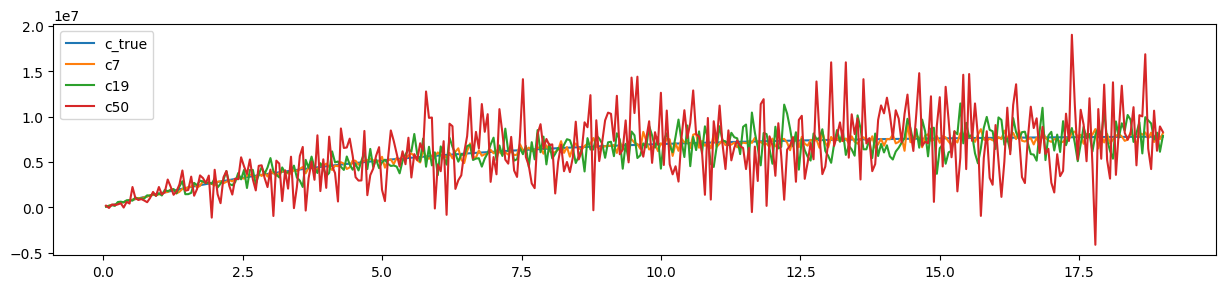

In [5]:
synthetic.plot(figsize=(15,3))

### Inverse at 3 noise levels

In [6]:
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit

# ============================================
# NOISE FUNCTION
# ============================================
def add_noise(C, noise_fraction, seed=None, floor=0.001):
    C = np.asarray(C, dtype=float)
    rng = np.random.default_rng(seed)
    sigma = noise_fraction * C + floor * np.max(C)
    return C + rng.normal(0.0, sigma, size=C.shape)

# ============================================
# TRUE PARAMETERS (SI)
# ============================================
D_true = 0.05 / 60.0
v_true = 0.01 / 60.0
lam    = 2.1e-6
F_true = 1000.0 / 60.0
H      = 19.0

C_inf_true = F_true / lam
a_true     = v_true / (2*D_true) + np.sqrt(v_true**2 / (4*D_true**2) + lam / D_true)

# ============================================
# SYNTHETIC DATA
# ============================================
z = np.linspace(0.05, H, 361)
C_true = C_inf_true * (1 - np.exp(-a_true * z))

noise_levels = {0.07: 'c7', 0.19: 'c19', 0.50: 'c50'}
seeds        = {0.07: 1,    0.19: 2,    0.50: 3}

synthetic = pd.DataFrame({'c_true': C_true}, index=z)
for eps, name in noise_levels.items():
    synthetic[name] = add_noise(C_true, eps, seed=seeds[eps])

# ============================================
# QSER SEQUENTIAL INVERSION
# ============================================
def qser_inverse(z, C_noisy, v_known, lam, z_c_frac=0.7):
    # ---- Step 1: F from the plateau ----
    mask = z > z_c_frac * z[-1]
    F_hat = lam * np.mean(C_noisy[mask])

    # ---- Step 2: S and E ----
    S_hat = (F_hat / v_known) * z
    E_hat = S_hat - C_noisy

    # ---- Step 3: a from the exponential fit to E ----
    def E_model(z, a):
        return (F_hat / v_known) * z - (F_hat / lam) * (1 - np.exp(-a * z))
    popt, _ = curve_fit(E_model, z, E_hat, p0=[a_true], bounds=(0, np.inf), maxfev=20000)
    a_hat = popt[0]

    # ---- Step 4: D from a, v, lambda ----
    D_hat = v_known / a_hat + lam / a_hat**2

    return F_hat, a_hat, D_hat, S_hat, E_hat

# ============================================
# RUN
# ============================================
print("=" * 92)
print("QSER SEQUENTIAL INVERSION (v known)")
print("=" * 92)
print(f"True:  F = {F_true:.4e}  a = {a_true:.4e}  D = {D_true:.4e}")
print(f"       v = {v_true:.4e}  lambda = {lam:.4e}")
print("-" * 92)
print(f"{'noise':>6} | {'F_hat':>11} {'err%':>7} | "
      f"{'a_hat':>11} {'err%':>7} | {'D_hat':>11} {'err%':>7}")
print("-" * 92)

err = lambda x, xt: abs(x - xt) / xt * 100

for eps, name in noise_levels.items():
    C_noisy = synthetic[name].values
    F_hat, a_hat, D_hat, S_hat, E_hat = qser_inverse(z, C_noisy, v_true, lam)

    print(f"{eps*100:>5.0f}% | "
          f"{F_hat:>11.4e} {err(F_hat, F_true):>6.2f}% | "
          f"{a_hat:>11.4e} {err(a_hat, a_true):>6.2f}% | "
          f"{D_hat:>11.4e} {err(D_hat, D_true):>6.2f}%")

print("-" * 92)

QSER SEQUENTIAL INVERSION (v known)
True:  F = 1.6667e+01  a = 2.1189e-01  D = 8.3333e-04
       v = 1.6667e-04  lambda = 2.1000e-06
--------------------------------------------------------------------------------------------
 noise |       F_hat    err% |       a_hat    err% |       D_hat    err%
--------------------------------------------------------------------------------------------
    7% |  1.5965e+01   4.21% |  2.3273e-01   9.83% |  7.5492e-04   9.41%
   19% |  1.5915e+01   4.51% |  2.3549e-01  11.14% |  7.4561e-04  10.53%
   50% |  1.6804e+01   0.83% |  2.2068e-01   4.15% |  7.9835e-04   4.20%
--------------------------------------------------------------------------------------------


## Inverse MOdeling with noise levels  Figure 4

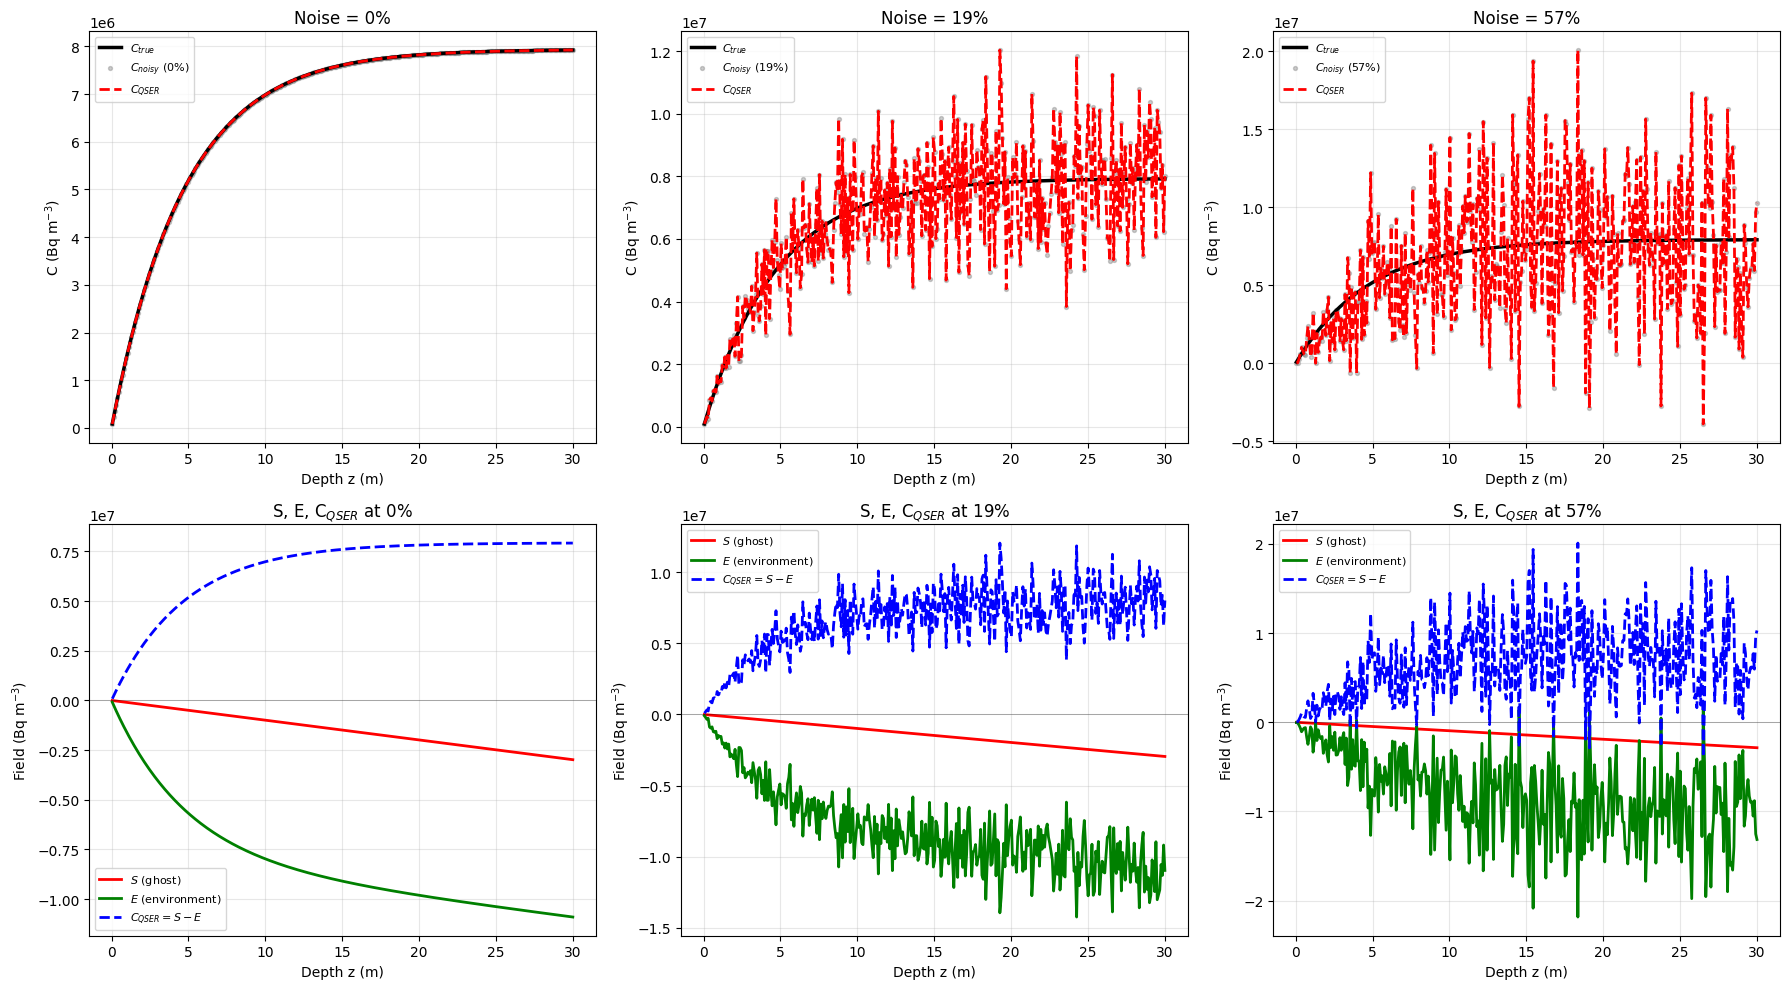

QSER SEQUENTIAL INVERSION (v known)
True:  F = 1.6667e+01   a = 2.1189e-01   D = 8.3333e-04
       v = -1.6667e-04   lambda = 2.1000e-06
------------------------------------------------------------------------------------------------
 noise |        F_hat     err% |        a_hat     err% |        D_hat     err%
------------------------------------------------------------------------------------------------
    0% |   1.6580e+01    0.52% |   2.1517e-01    1.55% |   8.1993e-04    1.61%
    7% |   1.6451e+01    1.30% |   2.1567e-01    1.78% |   8.1792e-04    1.85%
   19% |   1.6393e+01    1.64% |   2.2050e-01    4.06% |   7.9907e-04    4.11%
   38% |   1.7453e+01    4.72% |   2.0179e-01    4.77% |   8.7753e-04    5.30%
   57% |   1.5869e+01    4.79% |   2.2153e-01    4.55% |   7.9513e-04    4.58%
------------------------------------------------------------------------------------------------


In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# ============================================
# NOISE FUNCTION
# ============================================
def add_noise(C, noise_fraction, seed=None, floor=0.001):
    C = np.asarray(C, dtype=float)
    rng = np.random.default_rng(seed)
    sigma = noise_fraction * C + floor * np.max(C)
    return C + rng.normal(0.0, sigma, size=C.shape)

# ============================================
# TRUE PARAMETERS (SI)
# ============================================
D_true = 0.05 / 60.0
v_true = -0.01 / 60.0
lam    = 2.1e-6
F_true = 1000.0 / 60.0
H      = 30.0

C_inf_true = F_true / lam
a_true     = -v_true / (2*D_true) + np.sqrt(v_true**2 / (4*D_true**2) + lam / D_true)

# ============================================
# SYNTHETIC DATA
# ============================================
z = np.linspace(0.05, H, 361)
C_true = C_inf_true * (1 - np.exp(-a_true * z))

noise_levels = {0.00: 'c0', 0.07: 'c7', 0.19: 'c19',
                0.38: 'c38', 0.57: 'c57'}
seeds        = {0.00: 0,    0.07: 1,    0.19: 2,
                0.38: 4,    0.57: 5}

synthetic = pd.DataFrame({'c_true': C_true}, index=z)
for eps, name in noise_levels.items():
    if eps == 0.0:
        synthetic[name] = C_true.copy()
    else:
        synthetic[name] = add_noise(C_true, eps, seed=seeds[eps])

# ============================================
# QSER SEQUENTIAL INVERSION
# ============================================
def qser_inverse(z, C_noisy, v_known, lam, z_c_frac=0.7):
    mask = z > z_c_frac * z[-1]
    F_hat = lam * np.mean(C_noisy[mask])
    S_hat = (F_hat / v_known) * z
    E_hat = S_hat - C_noisy

    def E_model(z, a):
        return (F_hat / v_known) * z - (F_hat / lam) * (1 - np.exp(-a * z))
    popt, _ = curve_fit(E_model, z, E_hat, p0=[a_true],
                        bounds=(0, np.inf), maxfev=20000)
    a_hat = popt[0]
        # Convention B inversion for D
    D_hat = -v_known / a_hat + lam / a_hat**2

    return F_hat, a_hat, D_hat, S_hat, E_hat

# ============================================
# RUN PIPELINE
# ============================================
err = lambda x, xt: abs(x - xt) / xt * 100
results = {}
for eps, name in noise_levels.items():
    C_noisy = synthetic[name].values
    F_hat, a_hat, D_hat, S_hat, E_hat = qser_inverse(z, C_noisy, v_true, lam)
    C_qser = S_hat - E_hat
    results[name] = {
        'F_hat': F_hat, 'a_hat': a_hat, 'D_hat': D_hat,
        'S': S_hat, 'E': E_hat, 'C_qser': C_qser,
        'C_noisy': C_noisy,
        'err_F': err(F_hat, F_true),
        'err_a': err(a_hat, a_true),
        'err_D': err(D_hat, D_true),
    }

# ============================================
# FIGURE
# ============================================
panels = ['c0', 'c19', 'c57']
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for j, name in enumerate(panels):
    r = results[name]
    eps_pct = dict((v, k) for k, v in noise_levels.items())[name] * 100

    # Top panel: C vs z
    ax = axes[0, j]
    ax.plot(z, C_true, 'k-', lw=2.5, label='$C_{true}$')
    ax.scatter(z, r['C_noisy'], s=8, color='gray', alpha=0.4,
               label=f'$C_{{noisy}}$ ({eps_pct:.0f}%)')
    ax.plot(z, r['C_qser'], 'r--', lw=2, label='$C_{QSER}$')
    ax.set_xlabel('Depth z (m)')
    ax.set_ylabel('C (Bq m$^{-3}$)')
    ax.set_title(f'Noise = {eps_pct:.0f}%')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

    # Bottom panel: S, E, C_qser vs z
    ax = axes[1, j]
    ax.plot(z, r['S'], 'r-', lw=2, label='$S$ (ghost)')
    ax.plot(z, r['E'], 'g-', lw=2, label='$E$ (environment)')
    ax.plot(z, r['C_qser'], 'b--', lw=2, label='$C_{QSER} = S - E$')
    ax.axhline(0, color='k', lw=0.5, alpha=0.4)
    ax.set_xlabel('Depth z (m)')
    ax.set_ylabel('Field (Bq m$^{-3}$)')
    ax.set_title(f'S, E, C$_{{QSER}}$ at {eps_pct:.0f}%')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ============================================
# RECOVERY TABLE
# ============================================
print("=" * 96)
print("QSER SEQUENTIAL INVERSION (v known)")
print("=" * 96)
print(f"True:  F = {F_true:.4e}   a = {a_true:.4e}   D = {D_true:.4e}")
print(f"       v = {v_true:.4e}   lambda = {lam:.4e}")
print("-" * 96)
print(f"{'noise':>6} | {'F_hat':>12} {'err%':>8} | "
      f"{'a_hat':>12} {'err%':>8} | {'D_hat':>12} {'err%':>8}")
print("-" * 96)
for eps, name in noise_levels.items():
    r = results[name]
    print(f"{eps*100:>5.0f}% | "
          f"{r['F_hat']:>12.4e} {r['err_F']:>7.2f}% | "
          f"{r['a_hat']:>12.4e} {r['err_a']:>7.2f}% | "
          f"{r['D_hat']:>12.4e} {r['err_D']:>7.2f}%")
print("-" * 96)

# More QSER inverse methods for the problem

### Apply 3 inverse methods and get results statistics

Running ensemble (full case, N = 500, noise = [0, 19, 38, 57]%, 3 routes)...

TABLE 8: ENSEMBLE PARAMETER RECOVERY (FULL CASE, N = 500)
Bias % / Spread %
noise |      route |   F bias   F sprd |   a bias   a sprd |   D bias   D sprd
------------------------------------------------------------------------------
   0% |    plateau |    -0.52     0.00 |     1.55     0.00 |    -1.61     0.00
   0% |     direct |    -0.00     0.00 |     0.00     0.00 |     0.00     0.00
   0% |  iterative |    -0.00     0.00 |     0.00     0.00 |    -0.00     0.00
------------------------------------------------------------------------------
  19% |    plateau |    -0.60     1.73 |     1.92     6.17 |    -1.59     6.24
  19% |     direct |     0.00     1.40 |     0.13     5.09 |     0.15     5.37
  19% |  iterative |    -0.06     1.89 |     0.33     6.63 |     0.13     6.97
------------------------------------------------------------------------------
  38% |    plateau |    -0.46     3.71 |     1.99    12.

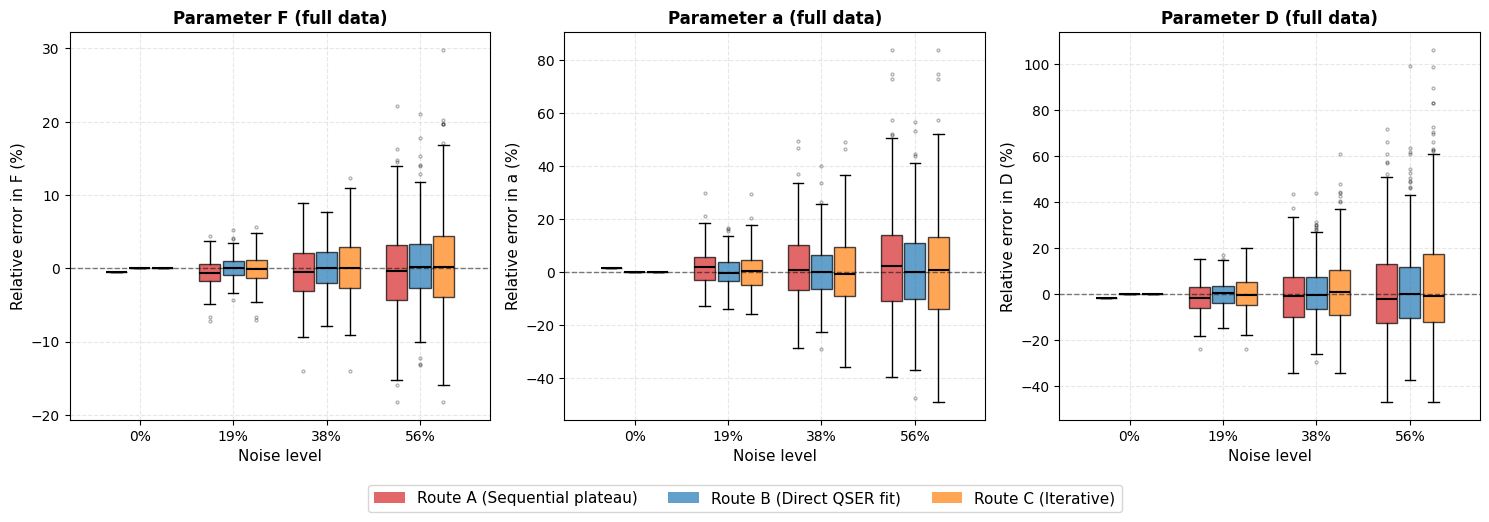

In [22]:
# ============================================================
# QSER ENSEMBLE — TABLE 8 AND BOXPLOT
# Scope: full-data case only.
# Noise levels: multiples of 19% (0, 19, 38, 57) —
#   same grid as Table 6.
# Produces:
#   (1) Table 8  — bias / spread over 500 realizations,
#                  4 noise levels, 3 routes, for (F, a, D)
#   (2) Boxplot  — relative error distributions, same data
# No test pass rates. No masked cases. No other outputs.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from matplotlib.patches import Patch

# ------------------------------------------------------------
# 1. True parameters (SI)
# ------------------------------------------------------------
D_true = 0.05 / 60.0          # m^2/s
v_true = -0.01 / 60.0         # m/s  (upward escape)
lam    = 2.1e-6               # 1/s
F_true = 1000.0 / 60.0        # Bq/m^3/s
H      = 30.0                 # m

C_inf_true = F_true / lam
a_true = (-v_true / (2 * D_true)
          + np.sqrt(v_true**2 / (4 * D_true**2) + lam / D_true))

z_full = np.linspace(0.05, H, 361)
C_full = C_inf_true * (1.0 - np.exp(-a_true * z_full))

# ------------------------------------------------------------
# 2. Noise model
# ------------------------------------------------------------
def add_noise(C, eps, seed=None, floor=0.001):
    rng = np.random.default_rng(seed)
    sigma = eps * C + floor * np.max(C)
    return C + rng.normal(0.0, sigma, size=C.shape)

# ------------------------------------------------------------
# 3. Three routes
# ------------------------------------------------------------
def route_A_sequential(z, C, v, lam, zc_frac=0.7):
    mask = z > zc_frac * z[-1]
    if np.sum(mask) < 3:
        mask = z > 0.5 * z[-1]
    F_hat = lam * np.mean(C[mask])
    S_hat = (F_hat / v) * z
    E_hat = S_hat - C

    def Emodel(z, a):
        return (F_hat / v) * z - (F_hat / lam) * (1.0 - np.exp(-a * z))

    try:
        popt, _ = curve_fit(Emodel, z, E_hat, p0=[a_true],
                            bounds=(0, np.inf), maxfev=20000)
        a_hat = popt[0]
    except Exception:
        return np.nan, np.nan, np.nan

    D_hat = -v / a_hat + lam / a_hat**2
    return F_hat, a_hat, D_hat

def route_B_direct(z, C, v, lam):
    def Cmodel(z, F, a):
        return (F / lam) * (1.0 - np.exp(-a * z))

    try:
        popt, _ = curve_fit(Cmodel, z, C,
                            p0=[F_true * 0.5, a_true * 0.5],
                            bounds=([0, 0], [np.inf, np.inf]),
                            maxfev=20000)
        F_hat, a_hat = popt
    except Exception:
        return np.nan, np.nan, np.nan

    D_hat = -v / a_hat + lam / a_hat**2
    return F_hat, a_hat, D_hat

def route_C_iterative(z, C, v, lam, zc_frac=0.7, n_iter=4, tol=1e-6):
    mask = z > zc_frac * z[-1]
    if np.sum(mask) < 3:
        mask = z > 0.5 * z[-1]

    F_hat = lam * np.mean(C[mask])
    a_hat = a_true

    for _ in range(n_iter):
        S_hat = (F_hat / v) * z
        E_hat = S_hat - C

        def Emodel(z, a):
            return (F_hat / v) * z - (F_hat / lam) * (1.0 - np.exp(-a * z))

        try:
            popt, _ = curve_fit(Emodel, z, E_hat, p0=[a_hat],
                                bounds=(0, np.inf), maxfev=20000)
            a_new = popt[0]
        except Exception:
            break

        zz = z[mask]
        w  = 1.0 - np.exp(-a_new * zz)
        Cinf = np.mean(C[mask] / (w + 1e-30))
        F_new = lam * Cinf

        if (abs(F_new - F_hat) / F_hat < tol
                and abs(a_new - a_hat) / a_hat < tol):
            F_hat, a_hat = F_new, a_new
            break
        F_hat, a_hat = F_new, a_new

    D_hat = -v / a_hat + lam / a_hat**2
    return F_hat, a_hat, D_hat

routes = {
    'plateau':   route_A_sequential,
    'direct':    route_B_direct,
    'iterative': route_C_iterative,
}

# ------------------------------------------------------------
# 4. Ensemble — noise levels are multiples of 19%
# ------------------------------------------------------------
N = 500
noise_levels = [0.00, 0.19, 0.38, 0.57]

params = {r: {eps: {'F': [], 'a': [], 'D': []} for eps in noise_levels}
          for r in routes}

print("Running ensemble (full case, N = 500, noise = "
      f"{[round(e*100) for e in noise_levels]}%, 3 routes)...")
for r_name, r_fn in routes.items():
    for eps in noise_levels:
        F_arr, a_arr, D_arr = [], [], []
        for k in range(N):
            C = C_full if eps == 0 else add_noise(
                C_full, eps, seed=1000 * int(eps * 100) + k)
            Fh, ah, Dh = r_fn(z_full, C, v_true, lam)
            if np.isnan(Fh):
                continue
            F_arr.append(Fh)
            a_arr.append(ah)
            D_arr.append(Dh)
        params[r_name][eps]['F'] = np.array(F_arr)
        params[r_name][eps]['a'] = np.array(a_arr)
        params[r_name][eps]['D'] = np.array(D_arr)

# ------------------------------------------------------------
# 5. Statistics helpers
# ------------------------------------------------------------
def rel_bias(mean, true):
    return 100.0 * (mean - true) / true

def rel_spread(std, true):
    return 100.0 * std / true

# ------------------------------------------------------------
# 6. Table 8
# ------------------------------------------------------------
def fmt_row(eps, r_name, arr):
    n = len(arr['F'])
    if n < 2:
        return f"{eps*100:>4.0f}% | {r_name:>10} | (n<2, skipped)"
    F_b = rel_bias(arr['F'].mean(), F_true)
    F_s = rel_spread(arr['F'].std(ddof=1), F_true)
    a_b = rel_bias(arr['a'].mean(), a_true)
    a_s = rel_spread(arr['a'].std(ddof=1), a_true)
    D_b = rel_bias(arr['D'].mean(), D_true)
    D_s = rel_spread(arr['D'].std(ddof=1), D_true)
    return (f"{eps*100:>4.0f}% | {r_name:>10} | "
            f"{F_b:>8.2f} {F_s:>8.2f} | "
            f"{a_b:>8.2f} {a_s:>8.2f} | "
            f"{D_b:>8.2f} {D_s:>8.2f}")

header = (f"{'noise':>5} | {'route':>10} | "
          f"{'F bias':>8} {'F sprd':>8} | "
          f"{'a bias':>8} {'a sprd':>8} | "
          f"{'D bias':>8} {'D sprd':>8}")
sep = "-" * len(header)

lines = []
lines.append("=" * len(header))
lines.append("TABLE 8: ENSEMBLE PARAMETER RECOVERY (FULL CASE, N = 500)")
lines.append("Bias % / Spread %")
lines.append("=" * len(header))
lines.append(header)
lines.append(sep)

for eps in noise_levels:
    for r_name in routes:
        lines.append(fmt_row(eps, r_name, params[r_name][eps]))
    lines.append(sep)

table_text = "\n".join(lines)
print("\n" + table_text)

with open('table8_full_case.txt', 'w') as f:
    f.write(table_text + "\n")
print("\nTable 8 written to 'table8_full_case.txt'")

# ------------------------------------------------------------
# 7. Sanity check — valid realizations per cell
# ------------------------------------------------------------
print("\nValid realizations per (route, noise):")
for r_name in routes:
    counts = [len(params[r_name][eps]['F']) for eps in noise_levels]
    print(f"  {r_name:>10}: {counts}")

# ------------------------------------------------------------
# 8. Boxplot figure
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
param_names = [('F', F_true), ('a', a_true), ('D', D_true)]
colors = {'plateau': '#d62728', 'direct': '#1f77b4', 'iterative': '#ff7f0e'}
labels = {'plateau':   'Route A (Sequential plateau)',
          'direct':    'Route B (Direct QSER fit)',
          'iterative': 'Route C (Iterative)'}

for ax, (pname, ptrue) in zip(axes, param_names):
    positions_base = np.arange(len(noise_levels))
    width = 0.25
    for j, r_name in enumerate(['plateau', 'direct', 'iterative']):
        data = []
        for eps in noise_levels:
            arr = params[r_name][eps][pname]
            if len(arr) > 0:
                data.append(100.0 * (arr - ptrue) / ptrue)
            else:
                data.append([])

        pos = positions_base + (j - 1) * width
        ax.boxplot(
            data, positions=pos, widths=width * 0.9,
            patch_artist=True,
            boxprops=dict(facecolor=colors[r_name], alpha=0.7),
            medianprops=dict(color='black', linewidth=1.5),
            flierprops=dict(marker='o', markersize=2, alpha=0.3),
        )

    ax.axhline(0, color='k', linestyle='--', lw=1, alpha=0.5)
    ax.set_xticks(positions_base)
    ax.set_xticklabels([f"{int(e*100)}%" for e in noise_levels])
    ax.set_xlabel('Noise level', fontsize=11)
    ax.set_ylabel(f'Relative error in {pname} (%)', fontsize=11)
    ax.set_title(f'Parameter {pname} (full data)', fontsize=12, fontweight='bold')
    ax.grid(True, alpha=0.3, linestyle='--')

legend_elements = [Patch(facecolor=colors[r], alpha=0.7, label=labels[r])
                   for r in ['plateau', 'direct', 'iterative']]
fig.legend(handles=legend_elements, loc='lower center', ncol=3,
           fontsize=11, bbox_to_anchor=(0.5, -0.05))

plt.tight_layout()
plt.subplots_adjust(bottom=0.15)
#plt.savefig('qser_boxplots.pdf', bbox_inches='tight', dpi=300)

